In [ ]:
# Fuel Efficiency Prediction

In [1]:
# Step 1: Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
# Step 2: Load dataset

In [4]:
df = pd.read_csv("automotive_regression_dataset.csv")

df.head()

,speed,acceleration,braking,mileage
0,34.157772,1.603424,0.931736,37.611989
1,49.707256,1.806978,2.186822,33.145521
2,52.325752,2.620780,1.648655,32.637948
3,84.175511,1.895130,2.408249,26.080386
4,43.492926,3.105762,2.128474,31.454574


In [5]:
# Step 3: Explore the dataset

In [6]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   speed         10000 non-null  float64
 1   acceleration  10000 non-null  float64
 2   braking       10000 non-null  float64
 3   mileage       10000 non-null  float64
dtypes: float64(4)
memory usage: 312.6 KB

Statistical Summary:
              speed  acceleration       braking       mileage
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      59.905726      2.993318      1.996655     29.064207
std       15.182827      0.981655      0.499470      4.210561
min       -3.408477     -0.876122      0.170823     14.399174
25%       49.572965      2.327770      1.664892     26.251110
50%       59.889755      3.006794      1.997726     29.054046
75%       70.279504      3.663331      2.331981     31.856791
max      117.065856      6.

In [7]:
# Step 4: Exploratory Data Analysis (EDA)

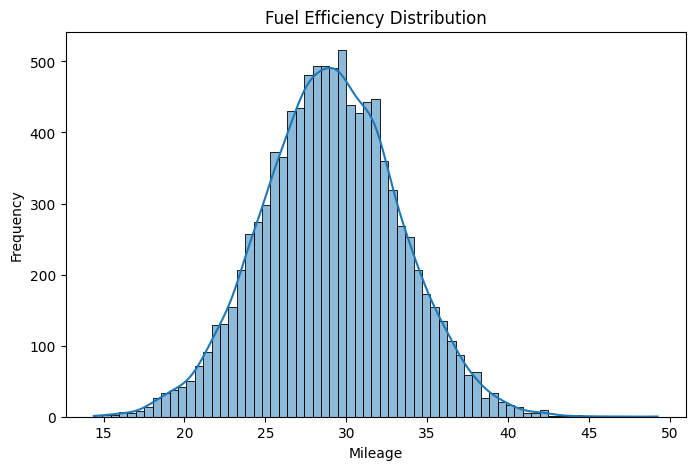

In [8]:
# A. Mileage distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["mileage"], kde=True)

plt.title("Fuel Efficiency Distribution")
plt.xlabel("Mileage")
plt.ylabel("Frequency")

plt.show()

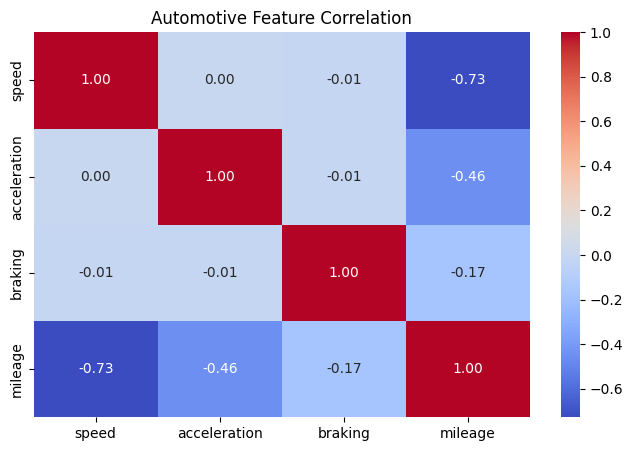

In [9]:
# B. Correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Automotive Feature Correlation")

plt.show()

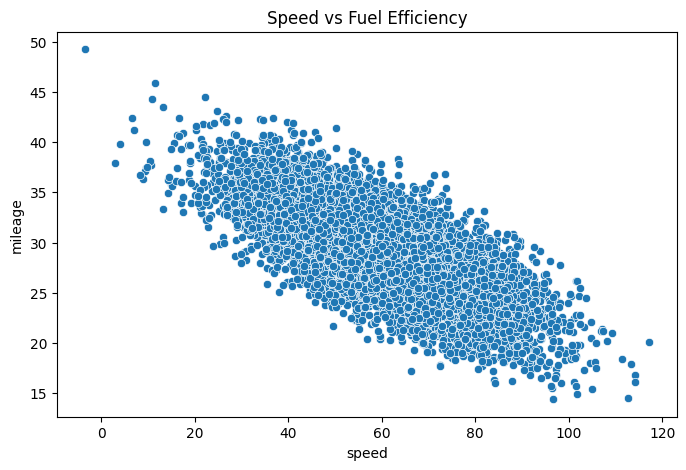

In [10]:
# C. Speed vs mileage
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="speed",
    y="mileage"
)

plt.title("Speed vs Fuel Efficiency")

plt.show()

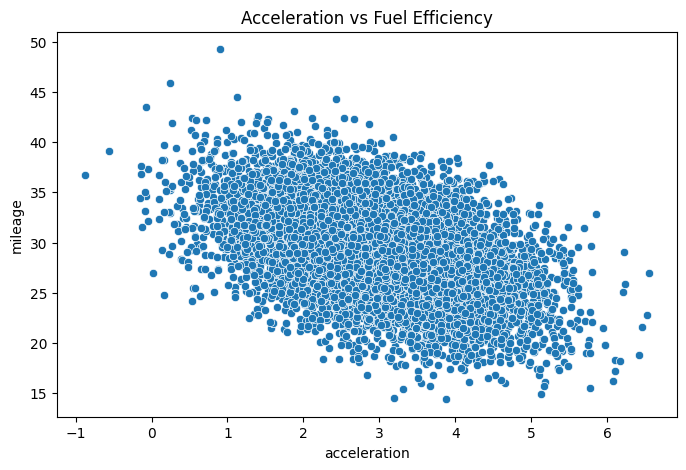

In [11]:
# D. Acceleration vs mileage
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="acceleration",
    y="mileage"
)

plt.title("Acceleration vs Fuel Efficiency")

plt.show()

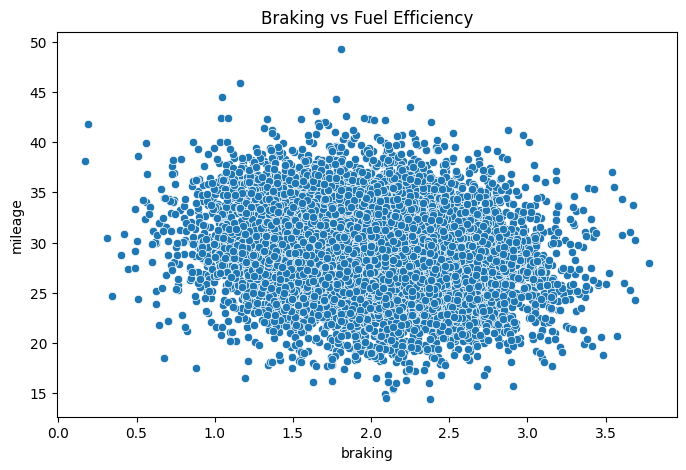

In [12]:
# E. Braking vs mileage
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="braking",
    y="mileage"
)

plt.title("Braking vs Fuel Efficiency")

plt.show()

In [13]:
# Step 5: Define independent and dependent variables

In [14]:
X = df[
    [
        "speed",
        "acceleration",
        "braking"
    ]
]

y = df["mileage"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
       speed  acceleration   braking
0  34.157772      1.603424  0.931736
1  49.707256      1.806978  2.186822
2  52.325752      2.620780  1.648655
3  84.175511      1.895130  2.408249
4  43.492926      3.105762  2.128474

Target:
0    37.611989
1    33.145521
2    32.637948
3    26.080386
4    31.454574
Name: mileage, dtype: float64


In [15]:
# Step 6: Split the dataset

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 3)
Testing Data: (2000, 3)


In [17]:
# Step 7: Build and train Linear Regression

In [18]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [19]:
# Step 8: Make predictions

In [20]:
y_pred = model.predict(X_test)

print("Actual Mileage:")
print(y_test.head(10).values)

print("\nPredicted Mileage:")
print(y_pred[:10])

Actual Mileage:
[36.67312997 35.50160943 22.35109686 32.4255831  26.12405939 28.1999058
 26.50062537 32.56853073 27.19114122 25.02856608]

Predicted Mileage:
[35.69077176 35.62905037 21.10574075 31.20677185 27.64175864 28.63484096
 28.774922   31.23679632 25.53593332 26.93378234]


In [21]:
# Step 9: Evaluate the model

In [22]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
-------------------------
MAE: 1.5957946764276643
MSE: 4.013272509084404
RMSE: 2.0033153793360654
R2 Score: 0.7632613152597927


In [23]:
# Step 10: Visualize actual vs predicted mileage

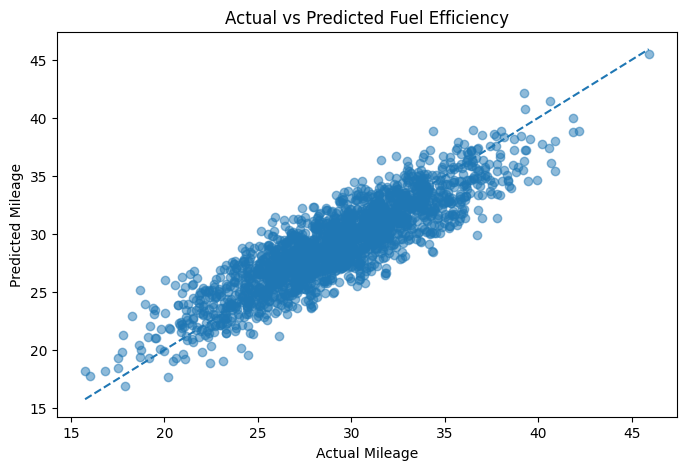

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Mileage")
plt.ylabel("Predicted Mileage")

plt.title("Actual vs Predicted Fuel Efficiency")

plt.show()

In [25]:
# Step 11: Predict mileage for a new vehicle

In [26]:
new_vehicle = pd.DataFrame({
    "speed": [60],
    "acceleration": [3.0],
    "braking": [2.0]
})

predicted_mileage = model.predict(new_vehicle)

print(
    "Predicted Fuel Efficiency:",
    round(predicted_mileage[0], 2)
)

Predicted Fuel Efficiency: 29.01


In [27]:
# Step 12: Display feature coefficients

In [28]:
regressor = model.named_steps["regressor"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_
})

print(coefficients)

print("\nIntercept:", regressor.intercept_)

        Feature  Coefficient
0         speed    -3.088233
1  acceleration    -1.914348
2       braking    -0.756526

Intercept: 29.019153439230934
